# Image Anomaly Detection (PatchCore-style)

Train on **good images only**, then flag images that contain anomalies and show *where* the anomaly is.

**Expected folder layout** (relative to the project root):
```
data/train/good/     <- your ~200 defect-free images
data/test/good/      <- defect-free test images
data/test/defect/    <- images with anomalies (any other folder inside data/test/ also counts as defect)
```

**How it works:** a frozen, pretrained ResNet turns every good image into a grid of patch features. A compressed subset is stored as a *memory bank*. For a new image, each patch is compared with its nearest neighbour in the bank; a big distance means "never seen in good images". No gradient training is needed, so it runs comfortably on an 8 GB MacBook.

Run the cells top to bottom. If you change the PyTorch environment, restart the kernel first.

In [ ]:
# Uncomment on the first run if packages are missing:
# %pip install torch torchvision numpy pillow scikit-learn matplotlib tqdm

## 1. Imports and settings

In [4]:
import os
os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK", "1")  # must be set BEFORE torch is imported (Apple GPU fallback)

import math, random, time
from pathlib import Path
from types import SimpleNamespace

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm
from sklearn.metrics import (average_precision_score, confusion_matrix, f1_score, precision_recall_curve,
                             precision_score, recall_score, roc_auc_score, roc_curve)

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.transforms import functional as TF

# Project root = parent folder if this notebook lives in notebooks/, otherwise the current folder
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

CFG = SimpleNamespace(
    data_root=ROOT / "data/seg",
    model_path=ROOT / "models" / "patchcore.pt",
    image_size=224,          # images are resized to image_size x image_size (raise to ~320 for tiny defects)
    batch_size=8,            # lower to 2-4 if you run out of memory
    backbone="resnet18",     # resnet18 (light) | resnet34 | resnet50 | wide_resnet50_2 (heavy, most accurate)
    layers=(2, 3),           # ResNet stages used for features
    coreset_ratio=0.1,       # share of patch features kept in the memory bank (lower = less memory)
    blur_sigma=4.0,          # smoothing of the anomaly heatmap
    val_fraction=0.1,        # good images held out to calibrate the threshold
    threshold_sigma=3.0,     # threshold = mean + sigma * std of held-out good scores
    seed=0,
    device="auto",           # auto | mps | cuda | cpu
)

def get_device(name="auto"):
    if name != "auto":
        return torch.device(name)
    if torch.cuda.is_available():
        return torch.device("cuda")
    if getattr(torch.backends, "mps", None) and torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

DEVICE = get_device(CFG.device)
seed_everything(CFG.seed)
print("project root:", ROOT)
print("device:", DEVICE)

project root: /Users/sarathchintalapati/Desktop/TakeHomeAssisment/anomaly-detection
device: mps


## 2. Data loading

In [5]:
IMG_EXTS = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff", ".webp"}
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

def list_images(folder):
    folder = Path(folder)
    if not folder.exists():
        return []
    return sorted(p for p in folder.rglob("*") if p.suffix.lower() in IMG_EXTS and not p.name.startswith("."))

def get_train_paths(data_root):
    root = Path(data_root) / "train"
    paths = list_images(root / "good") or list_images(root)
    if not paths:
        raise FileNotFoundError(f"No training images found in {root / 'good'}")
    return paths

def get_test_items(data_root):
    """data/test/good -> label 0; every other folder in data/test -> label 1 (defect)."""
    root = Path(data_root) / "test"
    paths, labels = [], []
    subdirs = sorted(p for p in root.iterdir() if p.is_dir()) if root.exists() else []
    for sub in subdirs:
        label = 0 if sub.name.lower() == "good" else 1
        for p in list_images(sub):
            paths.append(p); labels.append(label)
    if not paths:
        raise FileNotFoundError(f"No test images found in {root}")
    return paths, labels

def build_transform(image_size):
    return transforms.Compose([
        transforms.Resize((image_size, image_size)),
        transforms.ToTensor(),
        transforms.Normalize(MEAN, STD),
    ])

class ImageDataset(Dataset):
    def __init__(self, paths, labels, image_size):
        self.paths, self.labels = list(paths), list(labels)
        self.transform = build_transform(image_size)
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        img = Image.open(self.paths[i]).convert("RGB")
        return self.transform(img), self.labels[i], str(self.paths[i])

def make_loader(paths, labels, image_size, batch_size):
    return DataLoader(ImageDataset(paths, labels, image_size), batch_size=batch_size, shuffle=False, num_workers=0)

train_paths = get_train_paths(CFG.data_root)
test_paths, test_labels = get_test_items(CFG.data_root)
print(f"train/good: {len(train_paths)} images")
print(f"test: {test_labels.count(0)} good, {test_labels.count(1)} defect")

train/good: 54 images
test: 26 good, 13 defect


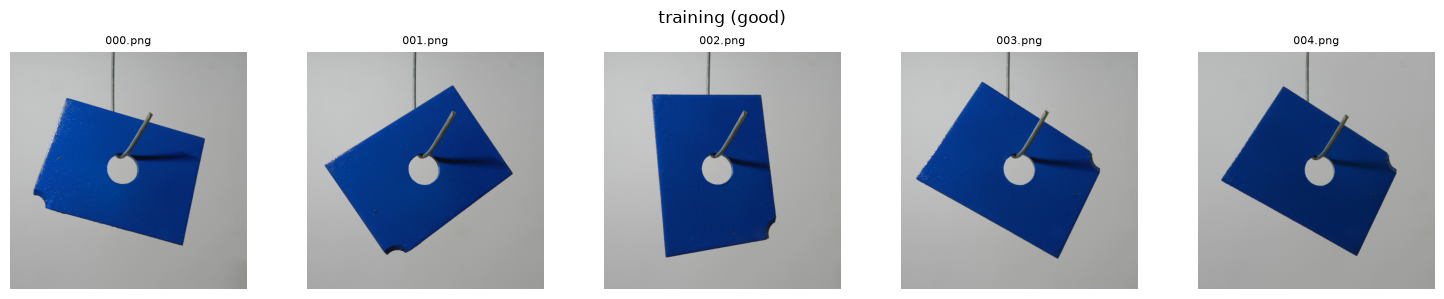

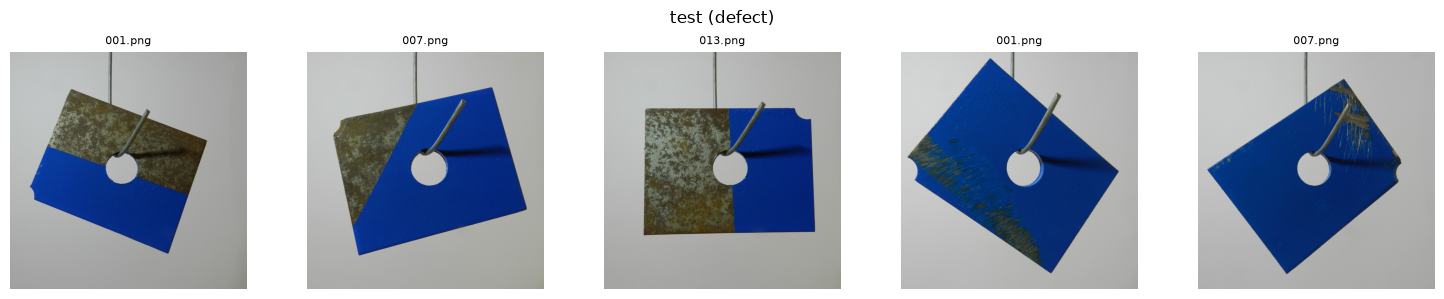

In [6]:
def show_samples(paths, n=5, title=""):
    paths = paths[:n]
    fig, axes = plt.subplots(1, len(paths), figsize=(3 * len(paths), 3))
    axes = np.atleast_1d(axes)
    for ax, p in zip(axes, paths):
        ax.imshow(Image.open(p).convert("RGB")); ax.set_title(Path(p).name, fontsize=8); ax.axis("off")
    fig.suptitle(title); plt.tight_layout(); plt.show()

show_samples(train_paths, 5, "training (good)")
show_samples([p for p, l in zip(test_paths, test_labels) if l == 1], 5, "test (defect)")

## 3. Model

* `FeatureExtractor`: frozen pretrained ResNet, returns a patch-feature grid.
* `greedy_coreset`: keeps a small but representative subset of all patch features.
* `PatchCoreDetector`: fit (build memory bank), predict (score + anomaly map), save/load.

In [7]:
class FeatureExtractor(nn.Module):
    def __init__(self, backbone="resnet18", layers=(2, 3), pretrained=True):
        super().__init__()
        net = torchvision.models.get_model(backbone, weights="DEFAULT" if pretrained else None)
        self.stem = nn.Sequential(net.conv1, net.bn1, net.relu, net.maxpool)
        self.stages = nn.ModuleList([net.layer1, net.layer2, net.layer3, net.layer4])
        self.layers = list(layers)
        self.eval()
        for p in self.parameters():
            p.requires_grad_(False)

    def train(self, mode=True):      # always stay in eval mode (frozen BatchNorm)
        return super().train(False)

    @torch.no_grad()
    def forward(self, x):            # -> (B, C, H, W)
        x = self.stem(x)
        feats = []
        for i, stage in enumerate(self.stages, start=1):
            x = stage(x)
            if i in self.layers:
                feats.append(F.avg_pool2d(x, kernel_size=3, stride=1, padding=1))   # local aggregation
            if i >= max(self.layers):
                break
        size = feats[0].shape[-2:]
        feats = [feats[0]] + [F.interpolate(f, size=size, mode="bilinear", align_corners=False) for f in feats[1:]]
        return torch.cat(feats, dim=1)


def greedy_coreset(x, n, device, proj_dim=128):
    """Greedy k-center selection on a random projection of the features. Returns selected indices."""
    N = x.shape[0]
    if n >= N:
        return torch.arange(N)
    proj = torch.randn(x.shape[1], proj_dim) / math.sqrt(proj_dim)
    z = (x @ proj).to(device)
    idx = torch.empty(n, dtype=torch.long, device=device)
    idx[0] = torch.randint(N, (1,)).item()
    min_d = ((z - z[idx[0]]) ** 2).sum(1)
    for i in tqdm(range(1, n), desc="coreset", leave=False):
        j = torch.argmax(min_d)
        idx[i] = j
        min_d = torch.minimum(min_d, ((z - z[j]) ** 2).sum(1))
    return idx.cpu()


class PatchCoreDetector:
    def __init__(self, backbone="resnet18", layers=(2, 3), image_size=224, coreset_ratio=0.1,
                 blur_sigma=4.0, device=torch.device("cpu"), pretrained=True):
        self.backbone, self.layers = backbone, list(layers)
        self.image_size, self.coreset_ratio, self.blur_sigma = image_size, coreset_ratio, blur_sigma
        self.device = device
        self.extractor = FeatureExtractor(backbone, layers, pretrained).to(device)
        self.bank = None         # (M, C) memory bank
        self.threshold = None    # decision threshold on the anomaly score
        self.val_stats = {}

    @torch.no_grad()
    def fit(self, loader):
        chunks = []
        for imgs, _, _ in tqdm(loader, desc="extracting features"):
            emb = self.extractor(imgs.to(self.device))
            chunks.append(emb.permute(0, 2, 3, 1).reshape(-1, emb.shape[1]).cpu())
        feats = torch.cat(chunks)
        n_keep = max(1, int(len(feats) * self.coreset_ratio))
        print(f"patch features: {len(feats):,} -> keeping {n_keep:,} ({self.coreset_ratio:.0%})")
        keep = greedy_coreset(feats, n_keep, self.device)
        self.bank = feats[keep].to(self.device)

    @torch.no_grad()
    def _nn_distance(self, patches, chunk=2048):
        out = []
        for i in range(0, patches.shape[0], chunk):
            out.append(torch.cdist(patches[i:i + chunk], self.bank).min(dim=1).values)
        return torch.cat(out)

    @torch.no_grad()
    def predict(self, imgs):
        """imgs: (B,3,H,W) normalized -> (scores (B,), anomaly_maps (B,H,W)), both on CPU."""
        assert self.bank is not None, "Model is not fitted/loaded."
        emb = self.extractor(imgs.to(self.device))
        B, C, H, W = emb.shape
        d = self._nn_distance(emb.permute(0, 2, 3, 1).reshape(-1, C)).reshape(B, 1, H, W)
        maps = F.interpolate(d, size=imgs.shape[-2:], mode="bilinear", align_corners=False).cpu()
        k = int(4 * self.blur_sigma) * 2 + 1
        maps = TF.gaussian_blur(maps, kernel_size=k, sigma=self.blur_sigma)
        return maps.flatten(1).max(dim=1).values, maps[:, 0]

    def score_loader(self, loader, desc="scoring"):
        return torch.cat([self.predict(imgs)[0] for imgs, _, _ in tqdm(loader, desc=desc, leave=False)])

    def save(self, path):
        Path(path).parent.mkdir(parents=True, exist_ok=True)
        torch.save({"bank": self.bank.cpu(), "backbone": self.backbone, "layers": self.layers,
                    "image_size": self.image_size, "coreset_ratio": self.coreset_ratio,
                    "blur_sigma": self.blur_sigma,
                    "threshold": None if self.threshold is None else float(self.threshold),
                    "val_stats": {k: float(v) for k, v in self.val_stats.items()}}, path)

    @classmethod
    def load(cls, path, device=torch.device("cpu")):
        ck = torch.load(path, map_location="cpu")
        det = cls(ck["backbone"], ck["layers"], ck["image_size"], ck["coreset_ratio"], ck["blur_sigma"], device=device)
        det.bank = ck["bank"].to(device)
        det.threshold = ck["threshold"]
        det.val_stats = ck.get("val_stats", {})
        return det

## 4. Train

Builds the memory bank from the good images (no gradient descent) and calibrates a threshold on a few held-out good images.

In [8]:
rng = np.random.RandomState(CFG.seed)
order = rng.permutation(len(train_paths))
n_val = int(round(len(train_paths) * CFG.val_fraction)) if len(train_paths) >= 10 else 0
val_paths = [train_paths[i] for i in order[:n_val]]
fit_paths = [train_paths[i] for i in order[n_val:]]
print(f"{len(fit_paths)} images for the memory bank, {len(val_paths)} held out for the threshold")

det = PatchCoreDetector(CFG.backbone, CFG.layers, CFG.image_size, CFG.coreset_ratio, CFG.blur_sigma, device=DEVICE)

t0 = time.time()
det.fit(make_loader(fit_paths, [0] * len(fit_paths), CFG.image_size, CFG.batch_size))
print(f"memory bank built in {time.time() - t0:.1f}s, shape {tuple(det.bank.shape)}")

49 images for the memory bank, 5 held out for the threshold


extracting features: 100%|██████████| 7/7 [00:02<00:00,  2.99it/s]


patch features: 38,416 -> keeping 3,841 (10%)


memory bank built in 8.5s, shape (3841, 384)


In [9]:
if val_paths:
    s = det.score_loader(make_loader(val_paths, [0] * len(val_paths), CFG.image_size, CFG.batch_size), "calibrating").numpy()
    det.threshold = float(s.mean() + CFG.threshold_sigma * s.std())
    det.val_stats = {"mean": s.mean(), "std": s.std(), "max": s.max()}
    print(f"held-out good scores: mean={s.mean():.3f} std={s.std():.3f} max={s.max():.3f}")
    print(f"threshold = mean + {CFG.threshold_sigma} * std = {det.threshold:.3f}")
else:
    print("Not enough images to hold out; set the threshold in the evaluation section.")

det.save(CFG.model_path)
print("saved model ->", CFG.model_path)

held-out good scores: mean=1.799 std=0.282 max=2.334
threshold = mean + 3.0 * std = 2.646
saved model -> /Users/sarathchintalapati/Desktop/TakeHomeAssisment/anomaly-detection/models/patchcore.pt


## 5. Evaluate on the test set

In [10]:
loader = make_loader(test_paths, test_labels, det.image_size, CFG.batch_size)
scores, maps = [], []
for imgs, lbls, ps in tqdm(loader, desc="testing"):
    s, m = det.predict(imgs)
    scores.extend(s.tolist()); maps.extend(m.numpy())
scores, y = np.array(scores), np.array(test_labels)
print("score range: good %.3f-%.3f | defect %.3f-%.3f" % (scores[y == 0].min(), scores[y == 0].max(),
                                                          scores[y == 1].min(), scores[y == 1].max()))

testing: 100%|██████████| 5/5 [00:01<00:00,  3.41it/s]

score range: good 1.495-2.090 | defect 2.663-3.099


ROC-AUC: 1.0000 | average precision: 1.0000
threshold in use: 2.646 | best-F1 threshold on test set: 2.663
precision 1.000 | recall 1.000 | F1 1.000
TN=26 FP=0 FN=0 TP=13
Note: with few defect images these numbers are noisy; the best-F1 threshold is optimistic.


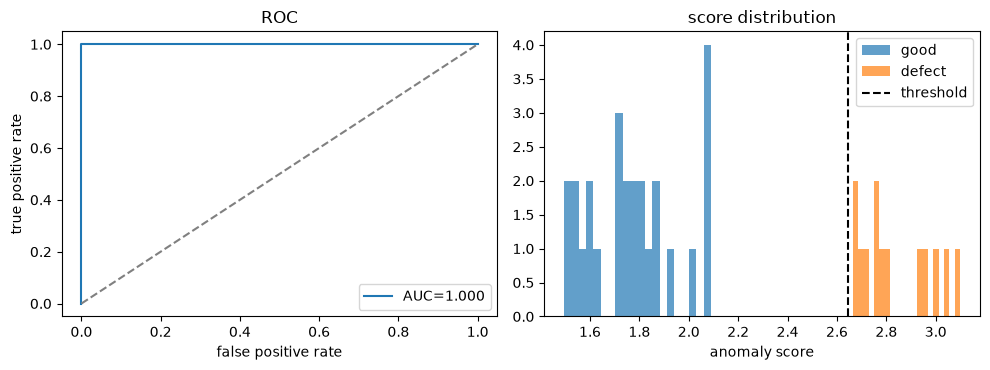

In [11]:
auc = roc_auc_score(y, scores)
prec, rec, thr = precision_recall_curve(y, scores)
f1s = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-12, None)
best_thr = float(thr[int(np.argmax(f1s))])

threshold = det.threshold if det.threshold is not None else best_thr   # <- change to use another threshold
pred = (scores >= threshold).astype(int)
tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()

print(f"ROC-AUC: {auc:.4f} | average precision: {average_precision_score(y, scores):.4f}")
print(f"threshold in use: {threshold:.3f} | best-F1 threshold on test set: {best_thr:.3f}")
print(f"precision {precision_score(y, pred, zero_division=0):.3f} | recall {recall_score(y, pred, zero_division=0):.3f} "
      f"| F1 {f1_score(y, pred, zero_division=0):.3f}")
print(f"TN={tn} FP={fp} FN={fn} TP={tp}")
print("Note: with few defect images these numbers are noisy; the best-F1 threshold is optimistic.")

fpr, tpr, _ = roc_curve(y, scores)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
ax[0].plot(fpr, tpr, label=f"AUC={auc:.3f}"); ax[0].plot([0, 1], [0, 1], "--", c="gray")
ax[0].set_xlabel("false positive rate"); ax[0].set_ylabel("true positive rate"); ax[0].legend(); ax[0].set_title("ROC")
ax[1].hist(scores[y == 0], bins=20, alpha=0.7, label="good"); ax[1].hist(scores[y == 1], bins=20, alpha=0.7, label="defect")
ax[1].axvline(threshold, c="k", ls="--", label="threshold"); ax[1].set_xlabel("anomaly score"); ax[1].legend()
ax[1].set_title("score distribution")
plt.tight_layout(); plt.show()

### Heatmaps

Red areas are the parts of the image the model finds most unusual. Defect images are shown first, then good images.

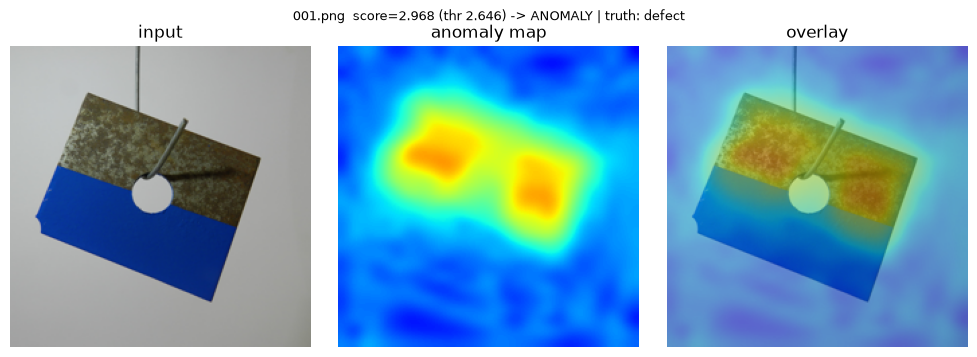

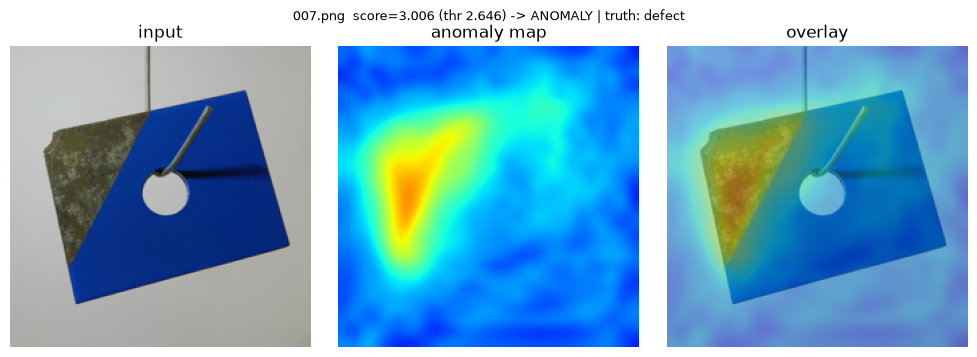

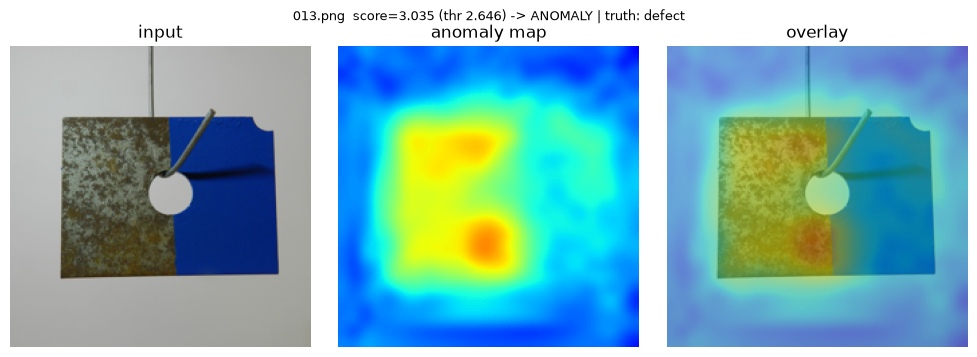

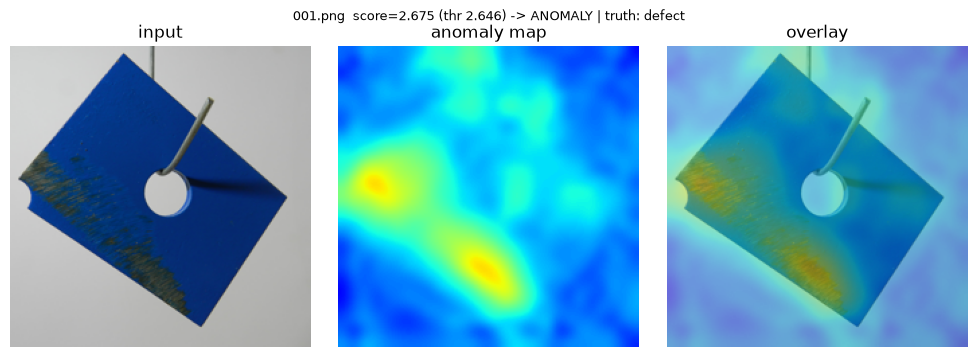

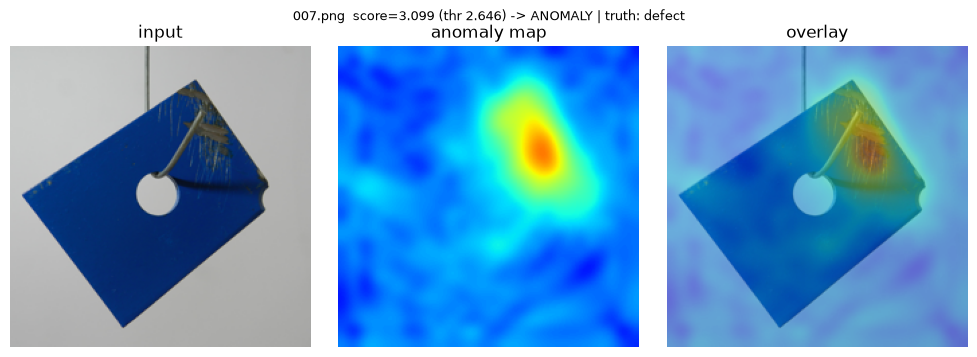

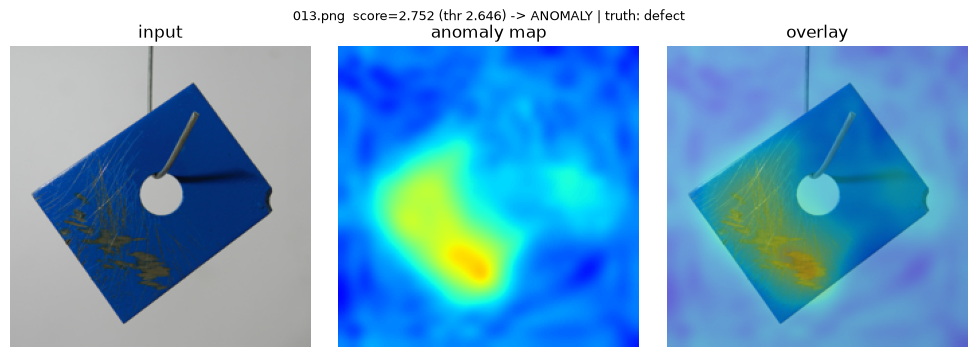

In [12]:
def show_result(path, amap, score, threshold, label=None):
    img = Image.open(path).convert("RGB").resize(amap.shape[::-1])
    vmax = max(float(amap.max()), threshold * 1.5, 1e-6)
    verdict = "ANOMALY" if score >= threshold else "OK"
    truth = "" if label is None else f" | truth: {'defect' if label else 'good'}"
    fig, axes = plt.subplots(1, 3, figsize=(10, 3.6))
    axes[0].imshow(img); axes[0].set_title("input")
    axes[1].imshow(amap, cmap="jet", vmin=0, vmax=vmax); axes[1].set_title("anomaly map")
    axes[2].imshow(img); axes[2].imshow(amap, cmap="jet", alpha=0.45, vmin=0, vmax=vmax); axes[2].set_title("overlay")
    for a in axes: a.axis("off")
    fig.suptitle(f"{Path(path).name}  score={score:.3f} (thr {threshold:.3f}) -> {verdict}{truth}", fontsize=9)
    plt.tight_layout(); plt.show()

N_SHOW = 6   # how many images to display
order_show = list(np.argsort(-y, kind="stable"))[:N_SHOW]   # defects first
for i in order_show:
    show_result(test_paths[i], maps[i], scores[i], threshold, label=int(y[i]))

## 6. Adjust the threshold (optional)

* Too many false alarms on good images -> raise the threshold.
* Defects missed -> lower it.

Set `new_threshold` and run the cell to store it in the saved model. `best_thr` (best F1 on the test set) is a reasonable starting point.

In [ ]:
new_threshold = best_thr      # or type a number, e.g. 1.85
det.threshold = float(new_threshold)
det.save(CFG.model_path)
print(f"threshold set to {det.threshold:.3f} and saved to {CFG.model_path}")

## 7. Predict on new images

Works for a single image file or a whole folder. Run this cell on its own later too: it reloads the saved model.

In [ ]:
def predict_images(input_path, model_path=CFG.model_path, threshold=None, show=True):
    detector = PatchCoreDetector.load(model_path, device=DEVICE)
    thr = threshold if threshold is not None else detector.threshold
    if thr is None:
        raise ValueError("No threshold stored in the model. Pass threshold=... or run section 6.")
    input_path = Path(input_path)
    paths = list_images(input_path) if input_path.is_dir() else [input_path]
    tf = build_transform(detector.image_size)
    results = []
    for p in paths:
        s, m = detector.predict(tf(Image.open(p).convert("RGB")).unsqueeze(0))
        s = float(s[0])
        verdict = "ANOMALY" if s >= thr else "ok"
        print(f"{p.name}: score={s:.3f} (threshold {thr:.3f}) -> {verdict}")
        if show:
            show_result(p, m[0].numpy(), s, thr)
        results.append((str(p), s, verdict))
    return results

# Example: point this at any image or folder
# predict_images(ROOT / "data" / "test" / "defect")
# predict_images("/path/to/new_image.png")

In [ ]:
predict_images()